# Results analysis: Poisson, Hawkes, Neural Hawkes, LogNormMix

This notebook **only reads results** written by `arrivalcast run`; it never trains anything, so it
runs in seconds and can be re-run whenever a new run finishes. (`experiments.ipynb` is left untouched.)

```
arrivalcast run --run-name baseline_v2 --seeds 0 1 2 --nhp-max-epochs 600
```

It reads from `results/<run-name>/`:

| File | Used in |
|---|---|
| `full_metric_evaluation.csv` | sections 1-8 (per source / model / seed metrics) |
| `model_comparison_results.csv` | section 9 (fitted Hawkes parameters) |
| `training_log.csv` | section 10 (epochs, cap hits, run time) |
| `test_predictions.parquet` *(optional)* | section 11 (per-event PIT, intervals, long-gap behaviour) |

**Sections**
1. Scoreboard and paired tests
2. NLL and CRPS by source
3. Head to head: LogNormMix vs Neural Hawkes
4. Seed-to-seed variability
5. Calibration of the predictive intervals
6. Point forecasts (MAE vs the lag-1 baseline)
7. SLA-hit classification
8. Results by schedule type
9. Hawkes diagnostics
10. Training diagnostics
11. Per-event diagnostics

**Reading conventions.** Neural models are summarised over seeds (mean, with the min-max range shown as a
bar). Raw NLL/CRPS are in *hours* and not comparable between sources, so cross-source summaries use
**differences in NLL** (nats per event; unchanged if you rescale time units) and **CRPS skill scores**
(`1 - CRPS/CRPS_Poisson`; positive = better than Poisson).

In [1]:
import sys, os, glob, json
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
%matplotlib inline

# ---- settings ---------------------------------------------------------------------------------
RUN_DIR = None            # e.g. "../results/baseline_v2". None = newest run folder under ../results
EXCLUDE_LOW_N = True      # headline statistics skip sources flagged low_n (shown hollow / with a dagger in plots)
SAVE_FIGURES = True       # writes PNG + PDF into <RUN_DIR>/figures/

# ---- locate the run ---------------------------------------------------------------------------
def find_run_dir(explicit):
    if explicit:
        return explicit
    found = sorted(glob.glob("../results/*/full_metric_evaluation.csv"), key=os.path.getmtime)
    if not found:
        raise FileNotFoundError(
            "No results found under ../results/. Run arrivalcast run first, or set RUN_DIR "
            "to a folder that contains full_metric_evaluation.csv.")
    return os.path.dirname(found[-1])

RUN_DIR = find_run_dir(RUN_DIR)
print("Using run:", RUN_DIR)

metrics = pd.read_csv(f"{RUN_DIR}/full_metric_evaluation.csv")
_opt = lambda name: pd.read_csv(f"{RUN_DIR}/{name}") if os.path.exists(f"{RUN_DIR}/{name}") else None
comparison = _opt("model_comparison_results.csv")
tlog = _opt("training_log.csv")
preds = pd.read_parquet(f"{RUN_DIR}/test_predictions.parquet") if os.path.exists(f"{RUN_DIR}/test_predictions.parquet") else None

if os.path.exists(f"{RUN_DIR}/config.json"):
    cfg_json = json.load(open(f"{RUN_DIR}/config.json"))
    print("LogNormMix config:", {k: cfg_json['lnm'][k] for k in ('hidden_dim', 'n_components', 'lr', 'max_epochs', 'chunk_len', 'batch_size')})
    print("NeuralHawkes max_epochs:", cfg_json['nhp']['max_epochs'])
print(f"{metrics.source_id.nunique()} sources | models: {sorted(metrics.model.unique())} | "
      f"neural seeds: {[int(x) for x in sorted(metrics.seed.dropna().unique())]} | "
      f"per-event predictions: {'yes' if preds is not None else 'no (section 11 will be skipped)'}")

FIG_DIR = os.path.join(RUN_DIR, "figures")
if SAVE_FIGURES:
    os.makedirs(FIG_DIR, exist_ok=True)
def savefig(fig, name):
    if SAVE_FIGURES:
        fig.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")
        fig.savefig(f"{FIG_DIR}/{name}.pdf", bbox_inches="tight")

Using run: ../results/final_syn
LogNormMix config: {'hidden_dim': 32, 'n_components': 4, 'lr': 0.003, 'max_epochs': 200, 'chunk_len': 128, 'batch_size': 16}
NeuralHawkes max_epochs: 600
25 sources | models: ['Hawkes', 'LogNormMix', 'NeuralHawkes', 'Poisson'] | neural seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | per-event predictions: yes


### Models, colours, and schedule groups

The group assignment below is **my reading of each source's `pattern_description`** (it is not stored in the
results), so edit `SOURCE_GROUPS` if you disagree. It follows the split your data description calls for:
regular, calendar-driven, bursty and heavy-tailed behaviour.

In [2]:
MODEL_ORDER = ["Poisson", "Hawkes", "NeuralHawkes", "LogNormMix"]
NEURAL = ["NeuralHawkes", "LogNormMix"]
SHORT = {"Poisson": "Poisson", "Hawkes": "Hawkes", "NeuralHawkes": "NHP", "LogNormMix": "LogNormMix"}
COLORS = {"Poisson": "#8c8c8c", "Hawkes": "#e69f00", "NeuralHawkes": "#0072b2", "LogNormMix": "#009e73"}  # colour-blind safe

SOURCE_GROUPS = {
    "Regular cadence":        ["SRC_01", "SRC_08", "SRC_09"],
    "Calendar-driven":        ["SRC_02", "SRC_03", "SRC_06", "SRC_07", "SRC_10", "SRC_11", "SRC_14"],
    "Low frequency":          ["SRC_04", "SRC_05", "SRC_12", "SRC_13", "SRC_15", "SRC_16", "SRC_17", "SRC_18", "SRC_23"],
    "Perturbed":              ["SRC_19", "SRC_20", "SRC_26"],     # outages, seasonal jitter, size-dependent delay
    # "Bursty" = bursts, correction files and self-excitation
    "Bursty":                 ["SRC_21", "SRC_22", "SRC_24"],
    "Heavy-tailed":           ["SRC_25"],
}
GROUP_ORDER = list(SOURCE_GROUPS) + ["Other"]
group_of = {s: g for g, ss in SOURCE_GROUPS.items() for s in ss}

# pattern descriptions (only for display); fine if the data folder is not available
patterns = {}
for f in glob.glob("../data/synthetic/*.csv"):
    head = pd.read_csv(f, nrows=1)
    patterns[head.source_id[0]] = head.pattern_description[0]

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 10})

In [3]:
# ---- one row per (source, model), averaged over seeds -----------------------------------------
agg = (metrics.groupby(["source_id", "model"], as_index=False)
       .agg(dataset=("dataset", "first"), n_test=("n_test_events", "first"), low_n=("low_n", "first"),
            nll=("mean_nll", "mean"), nll_min=("mean_nll", "min"), nll_max=("mean_nll", "max"), nll_sd=("mean_nll", "std"),
            crps=("mean_crps", "mean"), crps_min=("mean_crps", "min"), crps_max=("mean_crps", "max"),
            mae=("mae", "mean"), baseline_mae=("baseline_mae", "first"),
            cov50=("coverage_observed_50", "mean"), cov80=("coverage_observed_80", "mean"), cov90=("coverage_observed_90", "mean"),
            sla_acc=("sla_accuracy", "mean"), sla_f1=("sla_f1", "mean"), n_runs=("model", "size")))

src = agg.drop_duplicates("source_id").set_index("source_id")[["dataset", "n_test", "low_n"]]
src["group"] = [group_of.get(s, "BTS flight" if d != "synthetic" else "Other") for s, d in zip(src.index, src.dataset)]
if (src.group == "BTS flight").any():
    GROUP_ORDER.insert(-1, "BTS flight")
ORDER = [s for g in GROUP_ORDER for s in sorted(src.index[src.group == g])]
src = src.loc[ORDER]
src["label"] = [s + ("†" if low else "") for s, low in zip(src.index, src.low_n)]
VALID = list(src.index[~src.low_n]) if EXCLUDE_LOW_N else list(src.index)

def wide(col):
    return agg.pivot(index="source_id", columns="model", values=col).reindex(ORDER)[MODEL_ORDER]
nll, crps, cov80 = wide("nll"), wide("crps"), wide("cov80")

print(f"{len(ORDER)} sources; {len(VALID)} used for headline statistics "
      f"(† = low_n: {', '.join(src.index[src.low_n]) or 'none'})")
src.assign(pattern=[patterns.get(s, "") for s in src.index]).drop(columns="dataset")

25 sources; 21 used for headline statistics († = low_n: SRC_04, SRC_05, SRC_16, SRC_18)


,n_test,low_n,group,label,pattern
source_id,,,,,
SRC_01,109,False,Regular cadence,SRC_01,Daily at ~09:00 UTC — every calendar day
SRC_08,2631,False,Regular cadence,SRC_08,Hourly 24/7
SRC_09,438,False,Regular cadence,SRC_09,"Every 6 hours (00/06/12/18 UTC), every day"
SRC_02,109,False,Calendar-driven,SRC_02,"Daily at ~09:00 UTC, ~4h late on Wednesdays"
SRC_03,79,False,Calendar-driven,SRC_03,Weekdays only at ~14:00 UTC
SRC_06,47,False,Calendar-driven,SRC_06,"Tuesday, Wednesday, Thursday only at ~11:00 UTC"
SRC_07,75,False,Calendar-driven,SRC_07,Weekdays excluding US federal holidays at ~08:...
SRC_10,156,False,Calendar-driven,SRC_10,Twice daily on weekdays (~08:00 and ~18:00 UTC)
SRC_11,391,False,Calendar-driven,SRC_11,Business hours every 2h on weekdays (08/10/12/...


In [4]:
def group_bands(ax, order=ORDER, label_y=1.01):
    # light bands + titles marking the schedule groups along an x-axis of sources
    pos = {s: i for i, s in enumerate(order)}
    for gi, g in enumerate(GROUP_ORDER):
        members = [pos[s] for s in order if src.loc[s, "group"] == g]
        if not members:
            continue
        lo, hi = min(members) - 0.5, max(members) + 0.5
        if gi % 2 == 0:
            ax.axvspan(lo, hi, color="#000", alpha=0.045, zorder=0, lw=0)
        ax.text((lo + hi) / 2, label_y, g, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8, color="#444")

def source_ticks(ax, order=ORDER):
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(src.loc[order, "label"], rotation=90)
    ax.set_xlim(-0.6, len(order) - 0.4)
    ax.grid(axis="x", visible=False)

## 1. Scoreboard and paired tests

All statistics use per-source values averaged over seeds, on the sources not flagged `low_n`.
*NLL gain* = `NLL_Poisson - NLL_model` in nats per event (**positive = better than Poisson**).

In [5]:
v = VALID
board = pd.DataFrame({
    "median NLL (hours-scale)": nll.loc[v].median(),
    "median NLL gain vs Poisson": (nll.loc[v, "Poisson"].values[:, None] - nll.loc[v]).median(),
    "median CRPS skill vs Poisson": (1 - crps.loc[v].div(crps.loc[v, "Poisson"], axis=0)).median(),
    "mean NLL rank (1=best)": nll.loc[v].rank(axis=1).mean(),
    "median coverage @80%": cov80.loc[v].median(),
}).round(3)
board["sources where NLL is lowest"] = nll.loc[v].idxmin(axis=1).value_counts().reindex(MODEL_ORDER).fillna(0).astype(int)
board["sources where CRPS is lowest"] = crps.loc[v].idxmin(axis=1).value_counts().reindex(MODEL_ORDER).fillna(0).astype(int)
board.index.name = None
print(f"{len(v)} sources (low_n excluded: {EXCLUDE_LOW_N}); ties between Poisson and Hawkes go to Poisson")
board

21 sources (low_n excluded: True); ties between Poisson and Hawkes go to Poisson


,median NLL (hours-scale),median NLL gain vs Poisson,median CRPS skill vs Poisson,mean NLL rank (1=best),median coverage @80%,sources where NLL is lowest,sources where CRPS is lowest
Poisson,4.178,0.000,0.000,3.571,1.000,0,0
Hawkes,4.178,0.000,-0.000,3.429,1.000,0,0
NeuralHawkes,2.311,1.763,0.797,1.952,0.997,1,10
LogNormMix,1.140,3.315,0.761,1.048,0.809,20,11


In [6]:
pairs = [("LogNormMix", "NeuralHawkes"), ("LogNormMix", "Poisson"), ("NeuralHawkes", "Poisson"), ("Hawkes", "Poisson")]
rows = []
for table, name in ((nll, "NLL"), (crps, "CRPS")):
    for a, b in pairs:
        d = (table[a] - table[b]).loc[v].dropna()
        try:
            p = stats.wilcoxon(d).pvalue
        except ValueError:          # all differences are exactly zero
            p = np.nan
        rows.append({"metric": name, "A": a, "B": b, "A better on": f"{int((d < 0).sum())}/{len(d)} sources",
                     "A better by (median)": -d.median() if name == "NLL" else np.nan,
                     "median CRPS ratio A/B": (table[a] / table[b]).loc[v].median() if name == "CRPS" else np.nan,
                     "Wilcoxon p": p})
tests = pd.DataFrame(rows)
print("Paired Wilcoxon signed-rank across sources. Treat p-values as descriptive: sources are hand-designed to differ,")
print("not a random sample, and 3 seeds per neural model do not capture all training variance.")
tests.round(4)

Paired Wilcoxon signed-rank across sources. Treat p-values as descriptive: sources are hand-designed to differ,
not a random sample, and 3 seeds per neural model do not capture all training variance.


,metric,A,B,A better on,A better by (median),median CRPS ratio A/B,Wilcoxon p
0,NLL,LogNormMix,NeuralHawkes,20/21 sources,0.8864,NaN,0.0000
1,NLL,LogNormMix,Poisson,21/21 sources,3.3147,NaN,0.0000
2,NLL,NeuralHawkes,Poisson,21/21 sources,1.7634,NaN,0.0000
3,NLL,Hawkes,Poisson,12/21 sources,0.0000,NaN,0.5392
4,CRPS,LogNormMix,NeuralHawkes,11/21 sources,NaN,0.9433,0.9457
5,CRPS,LogNormMix,Poisson,21/21 sources,NaN,0.2386,0.0000
6,CRPS,NeuralHawkes,Poisson,20/21 sources,NaN,0.2027,0.0000
7,CRPS,Hawkes,Poisson,9/21 sources,NaN,1.0000,0.0888


In [7]:
# ---- data-driven headline sentences (these update themselves with the run) ----------------------
def count_better(table, a, b):
    d = (table[a] - table[b]).loc[v].dropna()
    return int((d < 0).sum()), len(d)

w, n = count_better(nll, "LogNormMix", "NeuralHawkes"); print(f"• NLL: LogNormMix beats Neural Hawkes on {w}/{n} sources.")
w, n = count_better(crps, "LogNormMix", "NeuralHawkes"); print(f"• CRPS: LogNormMix beats Neural Hawkes on {w}/{n} sources — "
                                                           f"{'the two metrics rank the models differently' if 0.3 < w / n < 0.7 else 'the metrics roughly agree'}.")
w, n = count_better(nll, "NeuralHawkes", "Poisson"); print(f"• Neural Hawkes beats Poisson on NLL on {w}/{n} sources.")
cov = cov80.loc[v].median().round(2).to_dict(); print(f"• Median coverage of the nominal 80% interval: " + ", ".join(f"{SHORT[m]} {cov[m]:.2f}" for m in MODEL_ORDER) + ".")
if tlog is not None:
    for m, g in tlog.groupby("model"):
        print(f"• {m}: {int(g.hit_cap.sum())}/{len(g)} runs stopped at the epoch cap (still improving).")

• NLL: LogNormMix beats Neural Hawkes on 20/21 sources.
• CRPS: LogNormMix beats Neural Hawkes on 11/21 sources — the two metrics rank the models differently.
• Neural Hawkes beats Poisson on NLL on 21/21 sources.
• Median coverage of the nominal 80% interval: Poisson 1.00, Hawkes 1.00, NHP 1.00, LogNormMix 0.81.
• LogNormMix: 28/250 runs stopped at the epoch cap (still improving).
• NeuralHawkes: 8/125 runs stopped at the epoch cap (still improving).


## 2. NLL and CRPS by source

**Figure 2a.** Raw NLL per source (lower is better). Dots are seed means; bars span the min-max over seeds
(neural models only); hollow markers = `low_n` sources. Because Poisson and Hawkes are nearly identical they are
drawn side by side. The y-axis is in hours-based nats, so only compare models *within* a source.

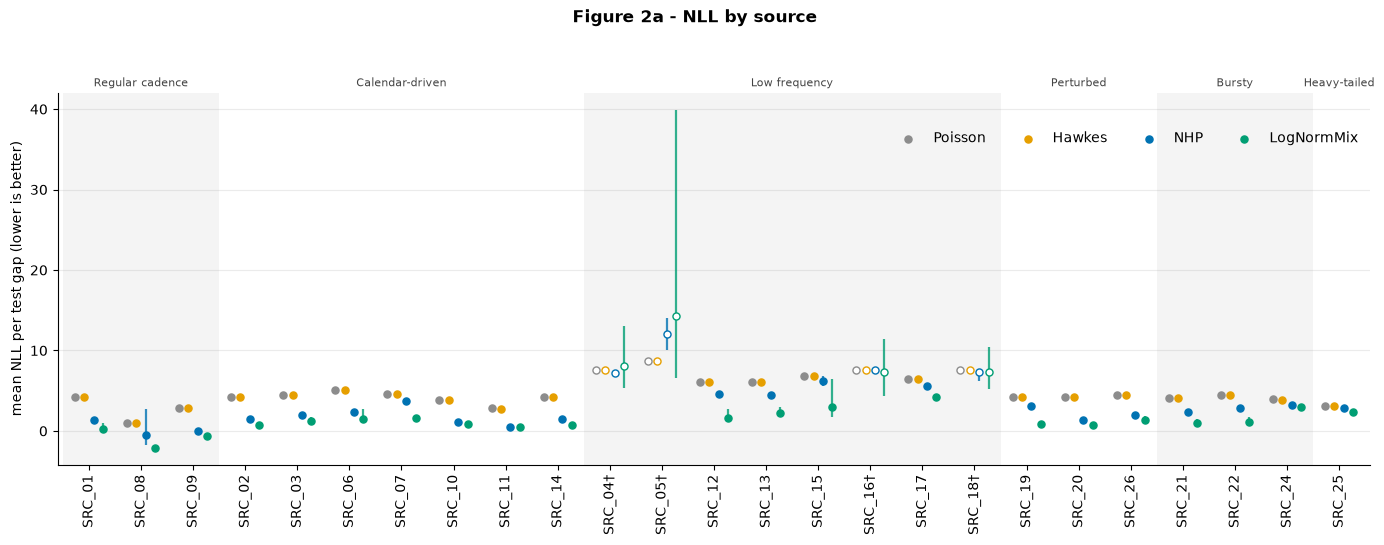

In [8]:
fig, ax = plt.subplots(figsize=(14, 5.2))
offs = dict(zip(MODEL_ORDER, [-0.27, -0.09, 0.09, 0.27]))
x = np.arange(len(ORDER))
for m in MODEL_ORDER:
    s = agg[agg.model == m].set_index("source_id").reindex(ORDER)
    xs, low = x + offs[m], s.low_n.values.astype(bool)
    ax.vlines(xs, s.nll_min, s.nll_max, color=COLORS[m], lw=1.6, alpha=0.8, zorder=2)
    ax.scatter(xs[~low], s.nll[~low], s=26, color=COLORS[m], zorder=3, label=SHORT[m])
    ax.scatter(xs[low], s.nll[low], s=26, facecolors="white", edgecolors=COLORS[m], zorder=3)
group_bands(ax); source_ticks(ax)
ax.set_ylabel("mean NLL per test gap (lower is better)")
ax.legend(ncol=4, loc="upper right", frameon=False, bbox_to_anchor=(1, 0.93))
fig.suptitle("Figure 2a - NLL by source", y=1.04, fontweight="bold"); fig.tight_layout()
savefig(fig, "fig2a_nll_by_source"); plt.show()

**Figure 2b.** Where each model beats Poisson. Left: NLL gain (nats per event; positive/blue = better than
Poisson). Right: CRPS skill score (`1 - CRPS/CRPS_Poisson`; 1 = perfect, 0 = same as Poisson, negative = worse).
Colour scales are clipped for readability; the printed numbers are exact.

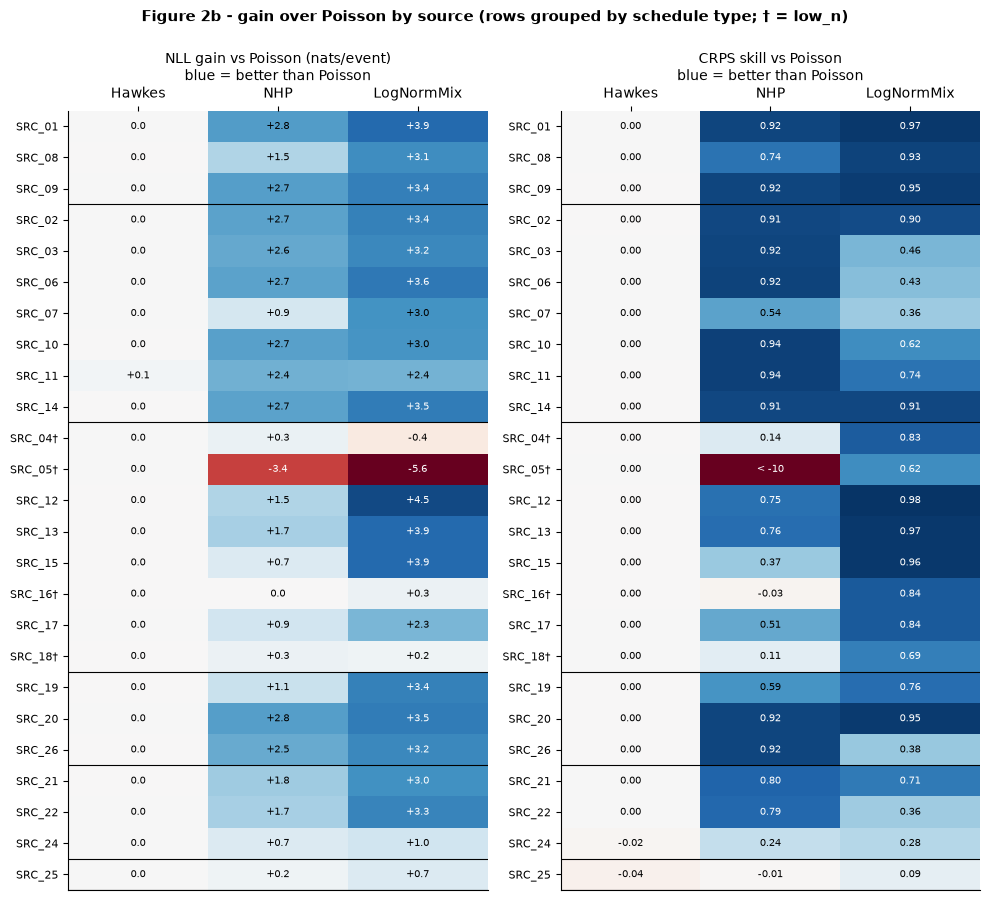

In [9]:
cmp_models = ["Hawkes", "NeuralHawkes", "LogNormMix"]
gain = (-nll[cmp_models]).add(nll["Poisson"], axis=0)
skill = 1 - crps[cmp_models].div(crps["Poisson"], axis=0)

def heat(ax, data, vlim, title, fmt):
    im = ax.imshow(data.values, cmap="RdBu", vmin=-vlim, vmax=vlim, aspect="auto")
    ax.set_xticks(range(len(cmp_models))); ax.set_xticklabels([SHORT[m] for m in cmp_models])
    ax.set_yticks(range(len(ORDER))); ax.set_yticklabels(src.loc[ORDER, "label"], fontsize=8)
    ax.xaxis.tick_top(); ax.grid(False); ax.set_title(title, pad=22, fontsize=10)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            val = data.values[i, j]
            ax.text(j, i, "" if np.isnan(val) else fmt(val), ha="center", va="center", fontsize=7.5,
                    color="white" if abs(val) > 0.6 * vlim else "black")
    return im

fig, axes = plt.subplots(1, 2, figsize=(10, 9))
fmt_gain = lambda x: "0.0" if abs(x) < 0.05 else f"{x:+.1f}"
fmt_skill = lambda x: "< -10" if x <= -10 else ("0.00" if abs(x) < 0.005 else f"{x:.2f}")
heat(axes[0], gain, 5, "NLL gain vs Poisson (nats/event)\nblue = better than Poisson", fmt_gain)
heat(axes[1], skill, 1, "CRPS skill vs Poisson\nblue = better than Poisson", fmt_skill)
# faint dividers between schedule groups
for ax in axes:
    edge = 0
    for g in GROUP_ORDER:
        k = int((src.group == g).sum())
        if k:
            edge += k
            ax.axhline(edge - 0.5, color="black", lw=0.8)
fig.suptitle("Figure 2b - gain over Poisson by source (rows grouped by schedule type; † = low_n)", y=0.995, fontweight="bold", fontsize=11)
fig.tight_layout(); savefig(fig, "fig2b_gain_over_poisson"); plt.show()

## 3. Head to head: LogNormMix vs Neural Hawkes

**Figure 3.** Per-source difference between the two neural models. Top: NLL(NHP) - NLL(LogNormMix).
Bottom: log2 of CRPS(NHP) / CRPS(LogNormMix). In both panels **positive (green) means LogNormMix is better,
negative (blue) means Neural Hawkes is better**. Thin whiskers are the widest possible gap given the seed ranges.
Bars are clipped at the axis limit (value printed). If the two panels disagree on a source, the models
trade off sharpness against tail behaviour there.

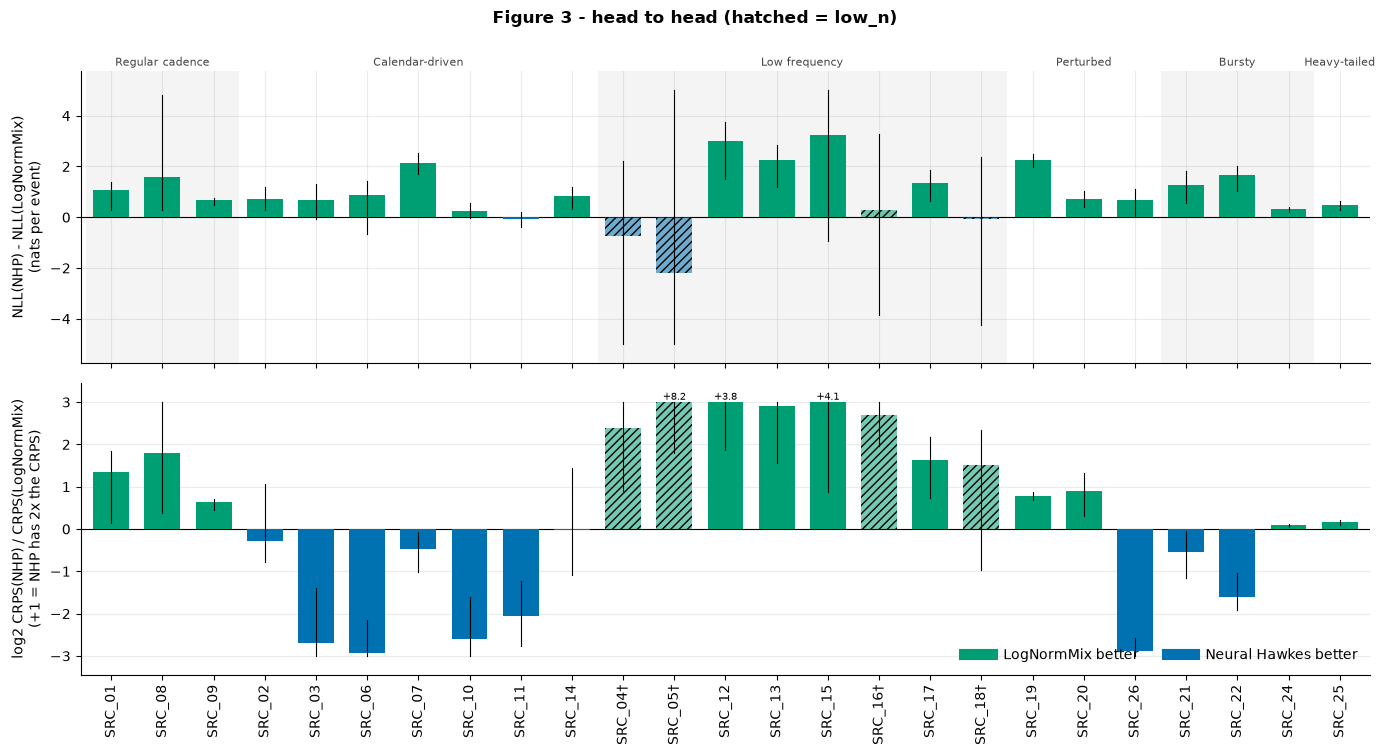

In [10]:
def seed_bounds(table_min, table_max, a, b):
    lo = (table_min[a] - table_max[b]); hi = (table_max[a] - table_min[b])
    return lo, hi

nll_min, nll_max = wide("nll_min"), wide("nll_max")
crps_min, crps_max = wide("crps_min"), wide("crps_max")
A, B = "NeuralHawkes", "LogNormMix"
d_nll = nll[A] - nll[B]
lo_n, hi_n = seed_bounds(nll_min, nll_max, A, B)
r_crps = np.log2(crps[A] / crps[B])
lo_c = np.log2(crps_min[A] / crps_max[B]); hi_c = np.log2(crps_max[A] / crps_min[B])

fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True)
for ax, val, lo, hi, clip, lab in ((axes[0], d_nll, lo_n, hi_n, 5, "NLL(NHP) - NLL(LogNormMix)\n(nats per event)"),
                                   (axes[1], r_crps, lo_c, hi_c, 3, "log2 CRPS(NHP) / CRPS(LogNormMix)\n(+1 = NHP has 2x the CRPS)")):
    vals = val.reindex(ORDER)
    shown = vals.clip(-clip, clip)
    colors = [COLORS["LogNormMix"] if x > 0 else COLORS["NeuralHawkes"] for x in vals]
    bars = ax.bar(range(len(ORDER)), shown, color=colors, width=0.7, zorder=3)
    for i, s in enumerate(ORDER):
        if src.loc[s, "low_n"]:
            bars[i].set_hatch("////"); bars[i].set_alpha(0.55)
        ax.plot([i, i], [np.clip(lo[s], -clip, clip), np.clip(hi[s], -clip, clip)], color="black", lw=0.8, zorder=4)
        if abs(vals[s]) > clip:
            ax.text(i, np.sign(vals[s]) * clip, f"{vals[s]:+.1f}", ha="center", va="bottom" if vals[s] > 0 else "top", fontsize=7)
    ax.axhline(0, color="black", lw=0.8); ax.set_ylim(-clip * 1.15, clip * 1.15); ax.set_ylabel(lab)
group_bands(axes[0]); source_ticks(axes[1])
axes[1].legend(handles=[Line2D([0], [0], color=COLORS["LogNormMix"], lw=8, label="LogNormMix better"),
                        Line2D([0], [0], color=COLORS["NeuralHawkes"], lw=8, label="Neural Hawkes better")],
               loc="lower right", frameon=False, ncol=2)
fig.suptitle("Figure 3 - head to head (hatched = low_n)", y=1.0, fontweight="bold"); fig.tight_layout()
savefig(fig, "fig3_head_to_head"); plt.show()

## 4. Seed-to-seed variability

**Figure 4.** Standard deviation of test NLL across seeds, per source, on a log axis. This is the noise floor:
a difference between models smaller than the seed spread should not be read as a real difference.
Large spreads on large sources point to unstable training rather than small-sample noise.

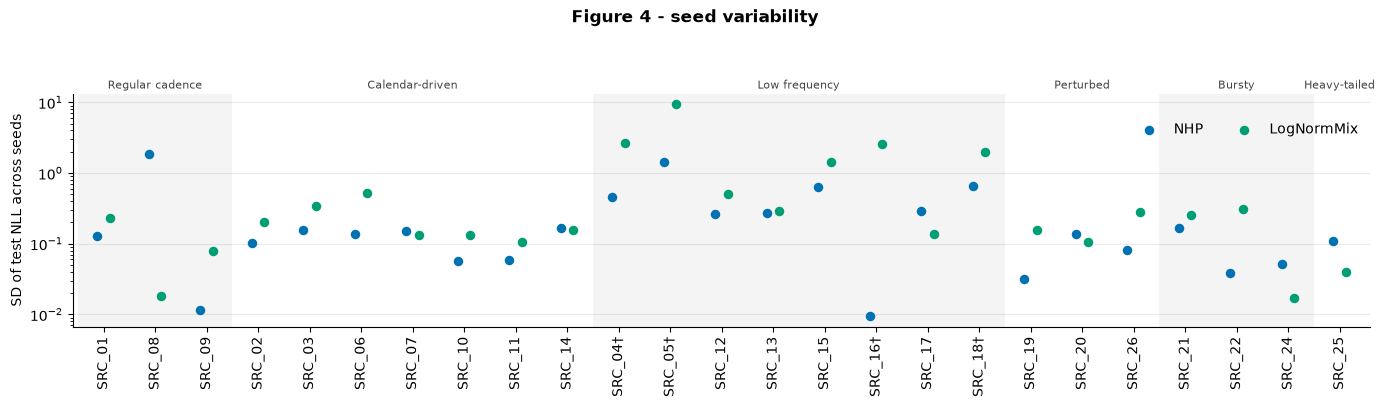

Largest seed spreads (NLL SD):


,model,SD
source_id,,
SRC_05,LogNormMix,9.40
SRC_04,LogNormMix,2.64
SRC_16,LogNormMix,2.58
SRC_18,LogNormMix,2.00
SRC_08,NeuralHawkes,1.84
SRC_05,NeuralHawkes,1.45


In [11]:
sd = agg[agg.model.isin(NEURAL)].pivot(index="source_id", columns="model", values="nll_sd").reindex(ORDER)
fig, ax = plt.subplots(figsize=(14, 3.8))
x = np.arange(len(ORDER))
for m, o in zip(NEURAL, (-0.12, 0.12)):
    ax.scatter(x + o, sd[m].clip(lower=1e-3), s=34, color=COLORS[m], label=SHORT[m], zorder=3)
ax.set_yscale("log"); ax.set_ylabel("SD of test NLL across seeds")
group_bands(ax); source_ticks(ax); ax.legend(frameon=False, loc="upper right", ncol=2, bbox_to_anchor=(1, 0.93))
fig.suptitle("Figure 4 - seed variability", y=1.06, fontweight="bold"); fig.tight_layout()
savefig(fig, "fig4_seed_variability"); plt.show()
print("Largest seed spreads (NLL SD):")
sd.stack().rename("SD").reset_index().rename(columns={"level_1": "model"}).sort_values("SD", ascending=False).head(6).round(2).set_index("source_id")

## 5. Calibration of the predictive intervals

**Figure 5a.** Observed coverage of the central 50/80/90% intervals, summarised over sources (line = median,
band = inter-quartile range). On the diagonal = calibrated; **above = intervals too wide** (conservative),
**below = too narrow** (overconfident). **Figure 5b.** The same at the 80% level, per source.

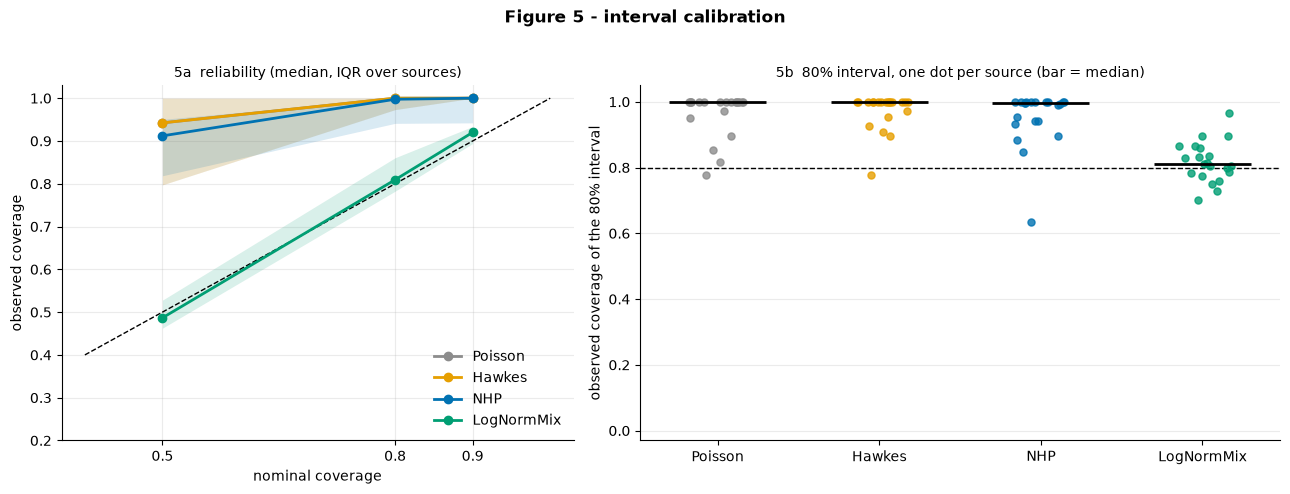

In [12]:
cov_cols = {0.5: "coverage_observed_50", 0.8: "coverage_observed_80", 0.9: "coverage_observed_90"}
ps = metrics.groupby(["source_id", "model"], as_index=False)[list(cov_cols.values())].mean()
ps = ps[ps.source_id.isin(VALID)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
ax.plot([0.4, 1], [0.4, 1], color="black", ls="--", lw=1)
for m in MODEL_ORDER:
    g = ps[ps.model == m]
    q = {nom: g[col].quantile([0.25, 0.5, 0.75]).values for nom, col in cov_cols.items()}
    noms = list(cov_cols)
    ax.plot(noms, [q[n][1] for n in noms], "-o", color=COLORS[m], label=SHORT[m], lw=2)
    ax.fill_between(noms, [q[n][0] for n in noms], [q[n][2] for n in noms], color=COLORS[m], alpha=0.15, lw=0)
ax.set_xlabel("nominal coverage"); ax.set_ylabel("observed coverage"); ax.set_xticks(list(cov_cols)); ax.set_ylim(0.2, 1.03)
ax.legend(frameon=False, loc="lower right"); ax.set_title("5a  reliability (median, IQR over sources)", fontsize=10)

ax = axes[1]
rng = np.random.default_rng(0)
for i, m in enumerate(MODEL_ORDER):
    vals = cov80.loc[v, m].dropna()
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(vals)), vals, s=26, color=COLORS[m], alpha=0.8, zorder=3)
    ax.hlines(vals.median(), i - 0.3, i + 0.3, color="black", lw=2, zorder=4)
ax.axhline(0.8, color="black", ls="--", lw=1)
ax.set_xticks(range(4)); ax.set_xticklabels([SHORT[m] for m in MODEL_ORDER]); ax.set_ylabel("observed coverage of the 80% interval")
ax.set_ylim(-0.03, 1.05); ax.set_title("5b  80% interval, one dot per source (bar = median)", fontsize=10); ax.grid(axis="x", visible=False)
fig.suptitle("Figure 5 - interval calibration", y=1.02, fontweight="bold"); fig.tight_layout()
savefig(fig, "fig5_calibration"); plt.show()

## 6. Point forecasts: MAE vs the lag-1 baseline

**Figure 6.** MAE of each model's median forecast divided by the MAE of the naive "same gap as last time"
baseline, one dot per source, log axis. **Below 1 beats the baseline.** (The CSV's `mae_pct_improvement` runs to
-1,000,000% when the baseline is almost perfect, which is unreadable; the ratio on a log axis shows the same
information.)

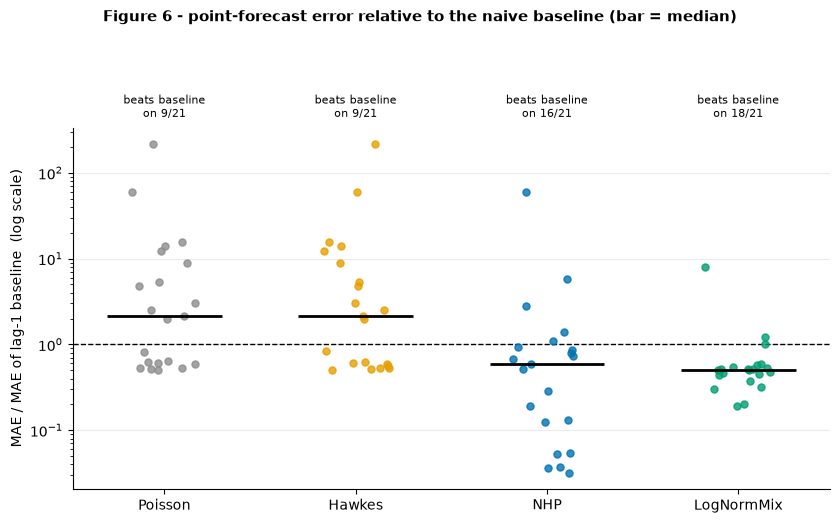

In [13]:
agg["mae_ratio"] = agg.mae / agg.baseline_mae
fig, ax = plt.subplots(figsize=(8.5, 4.8))
rng = np.random.default_rng(1)
for i, m in enumerate(MODEL_ORDER):
    vals = agg[(agg.model == m) & agg.source_id.isin(VALID)].mae_ratio.dropna()
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(vals)), vals, s=26, color=COLORS[m], alpha=0.8, zorder=3)
    ax.hlines(vals.median(), i - 0.3, i + 0.3, color="black", lw=2, zorder=4)
    ax.text(i, 1.02, f"beats baseline\non {(vals < 1).sum()}/{len(vals)}", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8)
ax.axhline(1, color="black", ls="--", lw=1); ax.set_yscale("log")
ax.set_xticks(range(4)); ax.set_xticklabels([SHORT[m] for m in MODEL_ORDER]); ax.grid(axis="x", visible=False)
ax.set_ylabel("MAE / MAE of lag-1 baseline  (log scale)")
fig.suptitle("Figure 6 - point-forecast error relative to the naive baseline (bar = median)", y=1.08, fontweight="bold", fontsize=11)
fig.tight_layout(); savefig(fig, "fig6_mae_vs_baseline"); plt.show()

## 7. SLA-hit classification

The SLA question is "does the next file arrive within `sla_threshold_hours`?" (24h in this run). That question
is **trivial for most sources**: hourly sources always hit it and weekly/monthly sources never do, so accuracy is
100% for everything and precision/recall are undefined. The figure therefore keeps only sources where the
Poisson accuracy is below 0.95, i.e. where there is something to predict. Accuracy is the share of correct
hit/miss calls; F1 is shown where it is defined.

13 informative sources: SRC_01, SRC_02, SRC_03, SRC_06, SRC_07, SRC_10, SRC_14, SRC_19, SRC_20, SRC_26, SRC_21, SRC_22, SRC_24


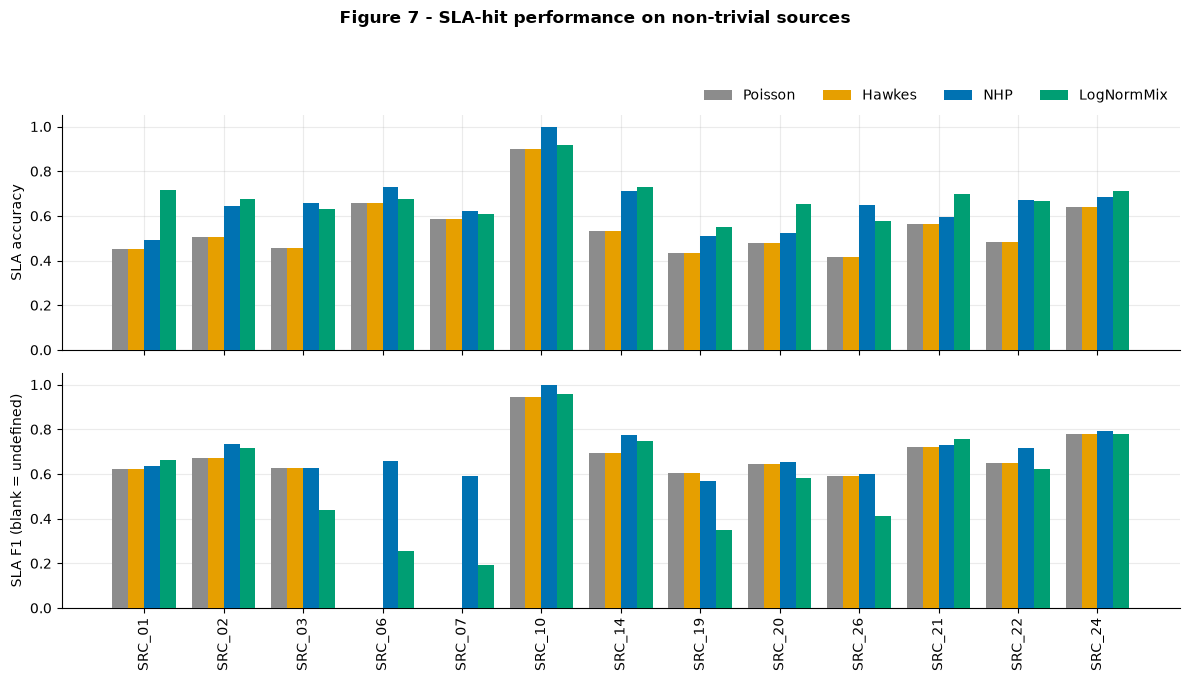

In [14]:
informative = [s for s in VALID if wide("sla_acc").loc[s, "Poisson"] < 0.95]
acc, f1 = wide("sla_acc").loc[informative], wide("sla_f1").loc[informative]
print(f"{len(informative)} informative sources:", ", ".join(informative))
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
x = np.arange(len(informative))
for ax, tab, lab in ((axes[0], acc, "SLA accuracy"), (axes[1], f1, "SLA F1 (blank = undefined)")):
    for m, o in zip(MODEL_ORDER, (-0.3, -0.1, 0.1, 0.3)):
        ax.bar(x + o, tab[m].fillna(0), width=0.2, color=COLORS[m], label=SHORT[m], zorder=3)
    ax.set_ylabel(lab); ax.set_ylim(0, 1.05)
axes[1].set_xticks(x); axes[1].set_xticklabels(informative, rotation=90); axes[1].grid(axis="x", visible=False)
axes[0].legend(ncol=4, frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0))
fig.suptitle("Figure 7 - SLA-hit performance on non-trivial sources", y=1.04, fontweight="bold"); fig.tight_layout()
savefig(fig, "fig7_sla"); plt.show()

## 8. Results by schedule type

**Figure 8.** NLL gain over Poisson for the two neural models, grouped by schedule type (one dot per source,
bar = group median). Most groups have only a handful of sources, so read this as a map of where to look, not as
a statistical result.

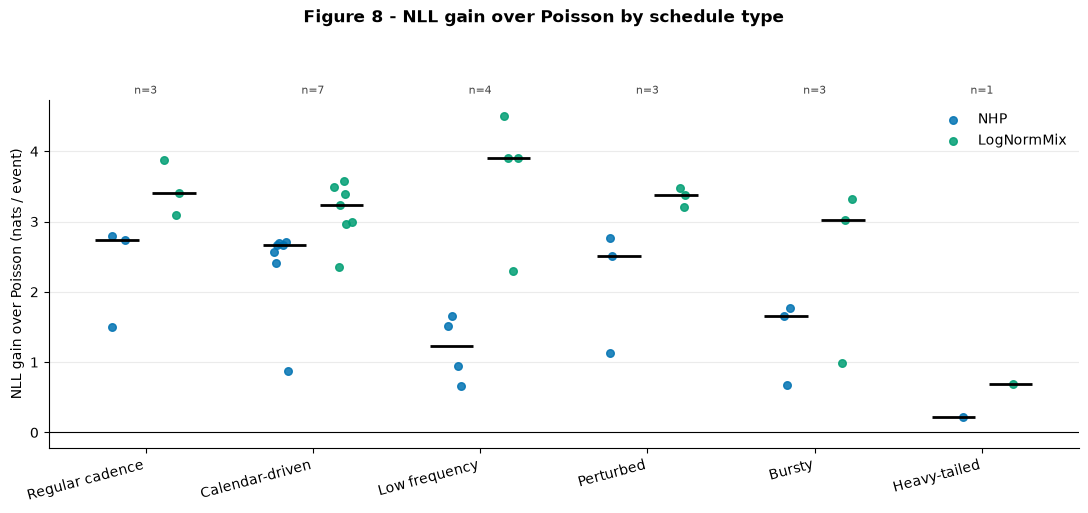

,NHP,LogNormMix,sources
median NLL gain vs Poisson,,,
Regular cadence,2.74,3.40,3
Calendar-driven,2.67,3.24,7
Low frequency,1.23,3.90,4
Perturbed,2.51,3.38,3
Bursty,1.66,3.03,3
Heavy-tailed,0.22,0.69,1


In [15]:
groups = [g for g in GROUP_ORDER if ((src.group == g) & src.index.isin(VALID)).any()]
fig, ax = plt.subplots(figsize=(11, 4.8))
rng = np.random.default_rng(2)
for gi, g in enumerate(groups):
    members = [s for s in src.index[src.group == g] if s in VALID]
    for m, o in zip(NEURAL, (-0.17, 0.17)):
        vals = gain.loc[members, m].dropna()
        ax.scatter(gi + o + rng.uniform(-0.07, 0.07, len(vals)), vals, s=30, color=COLORS[m], alpha=0.85, zorder=3,
                   label=SHORT[m] if gi == 0 else None)
        ax.hlines(vals.median(), gi + o - 0.13, gi + o + 0.13, color="black", lw=2, zorder=4)
    ax.text(gi, 1.01, f"n={len(members)}", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8, color="#444")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(groups))); ax.set_xticklabels(groups, rotation=15, ha="right"); ax.grid(axis="x", visible=False)
ax.set_ylabel("NLL gain over Poisson (nats / event)"); ax.legend(frameon=False)
fig.suptitle("Figure 8 - NLL gain over Poisson by schedule type", y=1.06, fontweight="bold"); fig.tight_layout()
savefig(fig, "fig8_by_group"); plt.show()
tbl = pd.concat({SHORT[m]: gain[m].loc[VALID].groupby(src.loc[VALID, "group"]).median() for m in NEURAL}, axis=1)
tbl["sources"] = src.loc[VALID].groupby("group").size()
tbl.reindex([g for g in GROUP_ORDER if g in tbl.index]).round(2).rename_axis("median NLL gain vs Poisson")

## 9. Hawkes diagnostics

If the fitted branching ratio (`alpha / beta`) is ~0 the Hawkes model has collapsed to a Poisson process and
adds nothing. A branching ratio near 1 means a near-critical process, which on a source with no true
self-excitation is more likely a poor fit than a discovery.

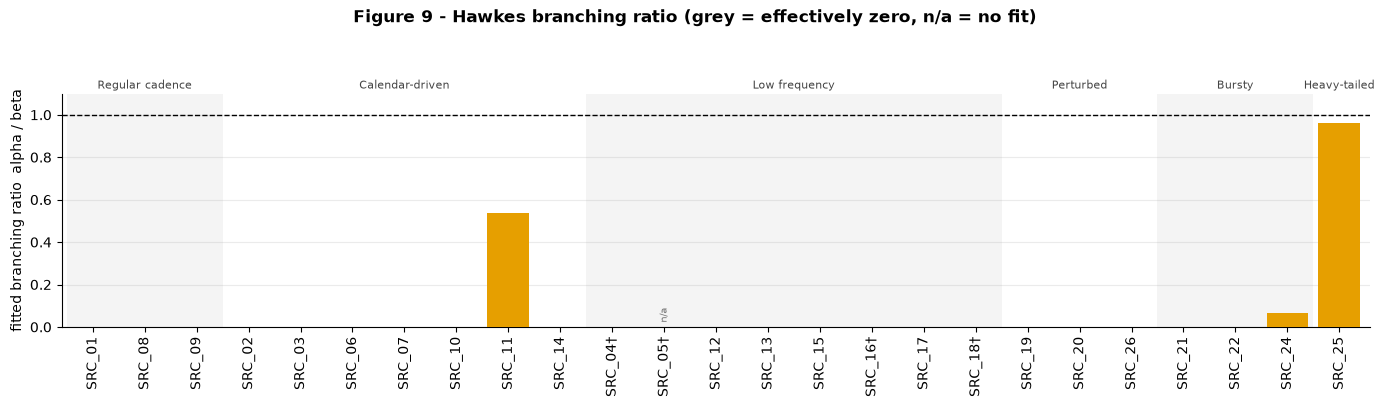

21 of 24 fitted sources have a branching ratio below 0.001 (Hawkes == Poisson there).
Sources where the Hawkes fit is not degenerate:


,mu,alpha,beta,branching_ratio,NLL gain vs Poisson
source_id,,,,,
SRC_11,0.069,0.175,0.327,0.535,0.127
SRC_24,0.053,0.093,1.417,0.066,0.027
SRC_25,0.005,0.018,0.019,0.960,0.016


In [16]:
if comparison is None or "branching_ratio" not in comparison:
    print("model_comparison_results.csv not available - skipping.")
else:
    hk = comparison[comparison.model == "Hawkes"].set_index("source_id").reindex(ORDER)
    missing = [s for s in ORDER if hk.loc[s, "branching_ratio"] != hk.loc[s, "branching_ratio"]]
    fig, ax = plt.subplots(figsize=(14, 3.8))
    br = hk.branching_ratio.fillna(0)
    ax.bar(range(len(ORDER)), br, color=[COLORS["Hawkes"] if b > 0.01 else "#cccccc" for b in br], zorder=3)
    for s in missing:
        ax.text(ORDER.index(s), 0.02, "n/a", rotation=90, ha="center", va="bottom", fontsize=7, color="#777")
    ax.axhline(1, color="black", ls="--", lw=1); ax.set_ylim(0, 1.1)
    group_bands(ax); source_ticks(ax); ax.set_ylabel("fitted branching ratio  alpha / beta")
    fig.suptitle("Figure 9 - Hawkes branching ratio (grey = effectively zero, n/a = no fit)", y=1.06, fontweight="bold"); fig.tight_layout()
    savefig(fig, "fig9_hawkes_branching"); plt.show()
    k0 = int((br < 1e-3).sum() - len(missing))
    print(f"{k0} of {len(ORDER) - len(missing)} fitted sources have a branching ratio below 0.001 (Hawkes == Poisson there).")
    out = hk.loc[hk.branching_ratio > 0.01, ["mu", "alpha", "beta", "branching_ratio"]].copy()
    out["NLL gain vs Poisson"] = gain.loc[out.index, "Hawkes"]
    print("Sources where the Hawkes fit is not degenerate:")
    display(out.round(3))

## 10. Training diagnostics

`hit_cap` means training ended because `max_epochs` ran out rather than because validation stopped improving,
i.e. the model may be under-trained. **Figure 10a**: wall-clock time per run (log axis). **Figure 10b**: the epoch
of the best validation loss for every run, by source (log axis). Two failure modes are marked: a **red ring** =
hit the epoch cap (still improving), and a **black cross** = best epoch of 1 or 2, i.e. validation never improved
on the starting point, so the model is essentially its initialisation. (Early stopping always runs `patience`
epochs past the best epoch, so epochs-run itself carries no extra information.)

,runs,hit_cap,median_epochs,median_best_epoch,median_seconds,max_seconds,total_minutes
model,,,,,,,
LogNormMix,250,28,94.0,74.0,4.3,34.2,21.3
NeuralHawkes,125,8,176.0,156.0,37.2,792.5,137.3


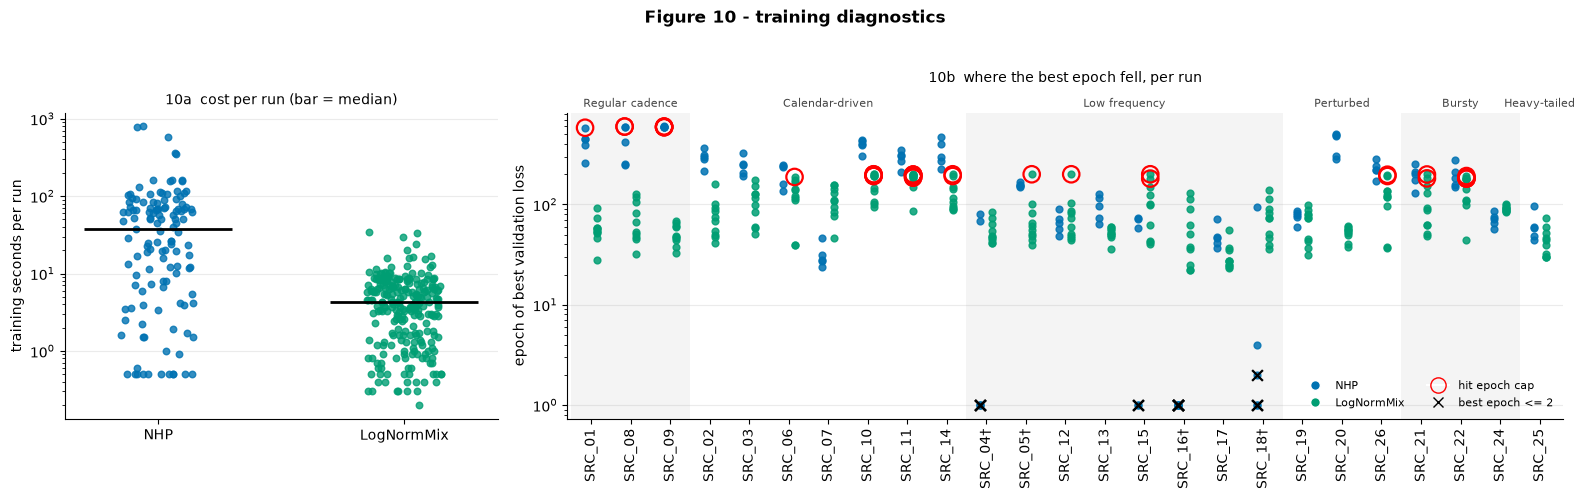

Runs that ended at the epoch cap (compare their NLL with the other seeds of the same source):


,model,seed,epochs_run,best_epoch,train_seconds,mean_nll,mean_crps,NLL SD over seeds
source_id,,,,,,,,
SRC_01,NeuralHawkes,1,600,582,129.2,1.24,0.38,0.13
SRC_05,LogNormMix,4,200,200,0.7,10.29,128.98,9.40
SRC_06,LogNormMix,9,200,188,8.8,1.18,10.47,0.53
SRC_08,NeuralHawkes,1,600,598,792.5,-0.56,0.06,1.84
SRC_08,NeuralHawkes,4,600,598,789.9,-1.79,0.02,1.84
SRC_09,NeuralHawkes,0,600,599,160.0,0.06,0.11,0.01
SRC_09,NeuralHawkes,1,600,588,158.9,0.05,0.11,0.01
SRC_09,NeuralHawkes,2,600,595,159.3,0.04,0.11,0.01
SRC_09,NeuralHawkes,3,600,593,158.6,0.07,0.11,0.01


Runs whose validation loss never improved after the first epoch (best_epoch <= 2). If the model's test NLL is close to Poisson's, training did not move it away from its initialisation. Check how large the validation split is for these sources:


,model,seed,best_epoch,epochs_run,model test NLL,Poisson test NLL (same source),n_test
source_id,,,,,,,
SRC_04,NeuralHawkes,0,1,21,7.60,7.58,3
SRC_04,NeuralHawkes,2,1,21,7.59,7.58,3
SRC_04,NeuralHawkes,4,1,21,7.59,7.58,3
SRC_15,NeuralHawkes,0,1,21,6.83,6.82,8
SRC_15,NeuralHawkes,2,1,21,6.84,6.82,8
SRC_16,NeuralHawkes,0,1,21,7.61,7.60,3
SRC_16,NeuralHawkes,1,1,21,7.61,7.60,3
SRC_16,NeuralHawkes,2,1,21,7.62,7.60,3
SRC_16,NeuralHawkes,3,1,21,7.61,7.60,3


In [17]:
if tlog is None:
    print("training_log.csv not available - skipping.")
else:
    summary = tlog.groupby("model").agg(runs=("source_id", "size"), hit_cap=("hit_cap", "sum"),
                                         median_epochs=("epochs_run", "median"), median_best_epoch=("best_epoch", "median"),
                                         median_seconds=("train_seconds", "median"), max_seconds=("train_seconds", "max"),
                                         total_minutes=("train_seconds", lambda s: s.sum() / 60)).round(1)
    display(summary)
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 2.3]})
    ax = axes[0]; rng = np.random.default_rng(3)
    for i, m in enumerate(NEURAL):
        t = tlog[tlog.model == m]
        ax.scatter(i + rng.uniform(-0.15, 0.15, len(t)), t.train_seconds, s=22, color=COLORS[m], alpha=0.8, zorder=3)
        ax.hlines(t.train_seconds.median(), i - 0.3, i + 0.3, color="black", lw=2, zorder=4)
    ax.set_yscale("log"); ax.set_xticks(range(2)); ax.set_xticklabels([SHORT[m] for m in NEURAL]); ax.set_ylabel("training seconds per run")
    ax.grid(axis="x", visible=False); ax.set_title("10a  cost per run (bar = median)", fontsize=10)
    ax = axes[1]
    pos = {sid: i for i, sid in enumerate(ORDER)}
    for m, o in zip(NEURAL, (-0.15, 0.15)):
        t = tlog[(tlog.model == m) & tlog.source_id.isin(pos)]
        xs = t.source_id.map(pos) + o
        ax.scatter(xs, t.best_epoch, s=24, color=COLORS[m], alpha=0.85, label=SHORT[m], zorder=3)
        c = t[t.hit_cap]
        ax.scatter(c.source_id.map(pos) + o, c.best_epoch, s=140, facecolors="none", edgecolors="red", lw=1.6, zorder=4)
        z = t[t.best_epoch <= 2]
        ax.scatter(z.source_id.map(pos) + o, z.best_epoch, marker="x", s=60, color="black", lw=1.6, zorder=5)
    ax.set_yscale("log"); ax.set_ylabel("epoch of best validation loss"); group_bands(ax); source_ticks(ax)
    ax.legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor=COLORS[m], markersize=7, label=SHORT[m]) for m in NEURAL]
              + [Line2D([0], [0], marker="o", color="w", markerfacecolor="none", markeredgecolor="red", markersize=11, label="hit epoch cap"),
                 Line2D([0], [0], marker="x", color="black", lw=0, markersize=7, label="best epoch <= 2")],
              frameon=False, loc="lower right", fontsize=8, ncol=2)
    ax.set_title("10b  where the best epoch fell, per run", fontsize=10, pad=22)
    fig.suptitle("Figure 10 - training diagnostics", y=1.03, fontweight="bold"); fig.tight_layout()
    savefig(fig, "fig10_training"); plt.show()

    capped = tlog[tlog.hit_cap][["source_id", "model", "seed", "epochs_run", "best_epoch", "train_seconds"]]
    if len(capped):
        key = metrics[["source_id", "model", "seed", "mean_nll", "mean_crps"]].assign(seed=lambda d: d.seed.astype("Int64"))
        capped = capped.assign(seed=capped.seed.astype("Int64")).merge(key, on=["source_id", "model", "seed"], how="left")
        others = (agg[agg.model.isin(NEURAL)].set_index(["source_id", "model"]).nll_sd.rename("NLL SD over seeds"))
        capped = capped.merge(others.reset_index(), on=["source_id", "model"], how="left")
        print("Runs that ended at the epoch cap (compare their NLL with the other seeds of the same source):")
        display(capped.round(2).set_index("source_id"))
    stuck = tlog[tlog.best_epoch <= 2]
    if len(stuck):
        val_col = "best_val_nll_per_event" if "best_val_nll_per_event" in stuck else "best_val_nll_per_gap"
        stuck = stuck.assign(seed=stuck.seed.astype("Int64")).merge(
            metrics[["source_id", "model", "seed", "mean_nll"]].assign(seed=lambda d: d.seed.astype("Int64")),
            on=["source_id", "model", "seed"], how="left")
        stuck["Poisson test NLL (same source)"] = stuck.source_id.map(nll["Poisson"])
        stuck["n_test"] = stuck.source_id.map(src.n_test)
        print("Runs whose validation loss never improved after the first epoch (best_epoch <= 2). If the model's test NLL is "
              "close to Poisson's, training did not move it away from its initialisation. Check how large the validation split is for these sources:")
        display(stuck[["source_id", "model", "seed", "best_epoch", "epochs_run", "mean_nll", "Poisson test NLL (same source)", "n_test"]]
                .rename(columns={"mean_nll": "model test NLL"}).round(2).set_index("source_id"))

## 11. Per-event diagnostics

These need `test_predictions.parquet` (one row per test event, written by the runner). They use the full
predictive distribution for each event, so they can show things the per-source averages hide.

In [18]:
PE_OK = preds is not None
if not PE_OK:
    print("No test_predictions.parquet in this run directory, so section 11 is skipped.\n"
          "Re-run arrivalcast run (current version) with a new --run-name to produce it.")
else:
    P = preds[preds.source_id.isin(VALID)].copy()
    P["seed_key"] = P.seed.astype("Int64").astype(str)
    print(f"{len(P):,} test-event rows | sources: {P.source_id.nunique()} | models: {sorted(P.model.unique())}")

87,397 test-event rows | sources: 21 | models: ['Hawkes', 'LogNormMix', 'NeuralHawkes', 'Poisson']


**Figure 11a - PIT histograms.** The PIT value is the model's predictive CDF evaluated at the true gap. If the
model is calibrated these are uniform (flat at 1). A hump in the middle means intervals are too wide; a U-shape
means too narrow; mass piled on one side means a biased forecast (left = actual gaps shorter than predicted).
Each source gets equal total weight, so large sources do not dominate.

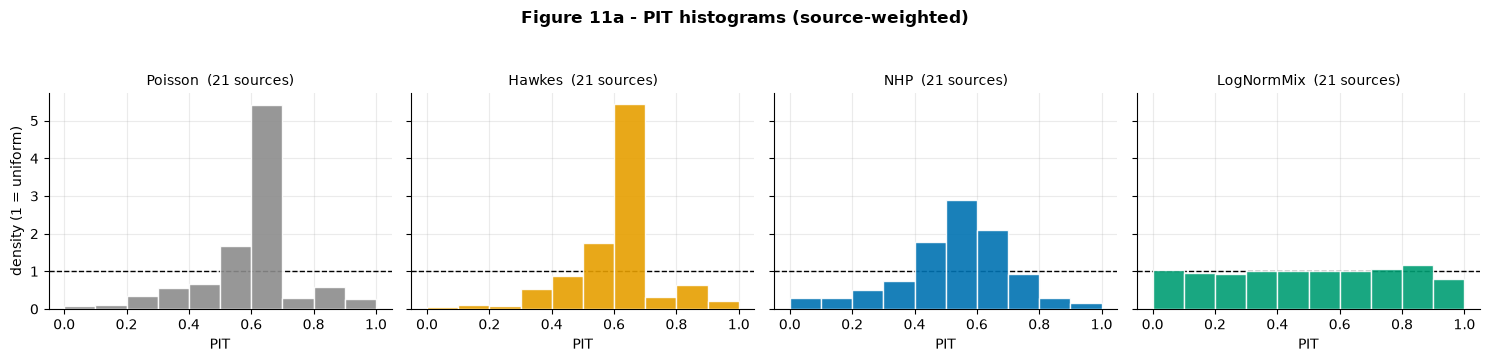

In [19]:
if PE_OK:
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
    for ax, m in zip(axes, MODEL_ORDER):
        g = P[P.model == m]
        if g.empty:
            ax.set_visible(False); continue
        w = 1.0 / g.groupby("source_id").pit.transform("size")
        h, edges = np.histogram(g.pit, bins=10, range=(0, 1), weights=w, density=True)
        ax.bar(edges[:-1], h, width=0.1, align="edge", color=COLORS[m], alpha=0.9, edgecolor="white", zorder=3)
        ax.axhline(1, color="black", ls="--", lw=1)
        ax.set_title(f"{SHORT[m]}  ({g.source_id.nunique()} sources)", fontsize=10); ax.set_xlabel("PIT")
    axes[0].set_ylabel("density (1 = uniform)")
    fig.suptitle("Figure 11a - PIT histograms (source-weighted)", y=1.05, fontweight="bold"); fig.tight_layout()
    savefig(fig, "fig11a_pit"); plt.show()

**Figure 11b - predictions over time for one source.** Dots are the actual gaps; the white diamond is the median forecast, and the bars are the central 50% (thick) and 90% (thin) intervals for each event. Set `PE_SOURCE` / `PE_SEED` to look at another source.

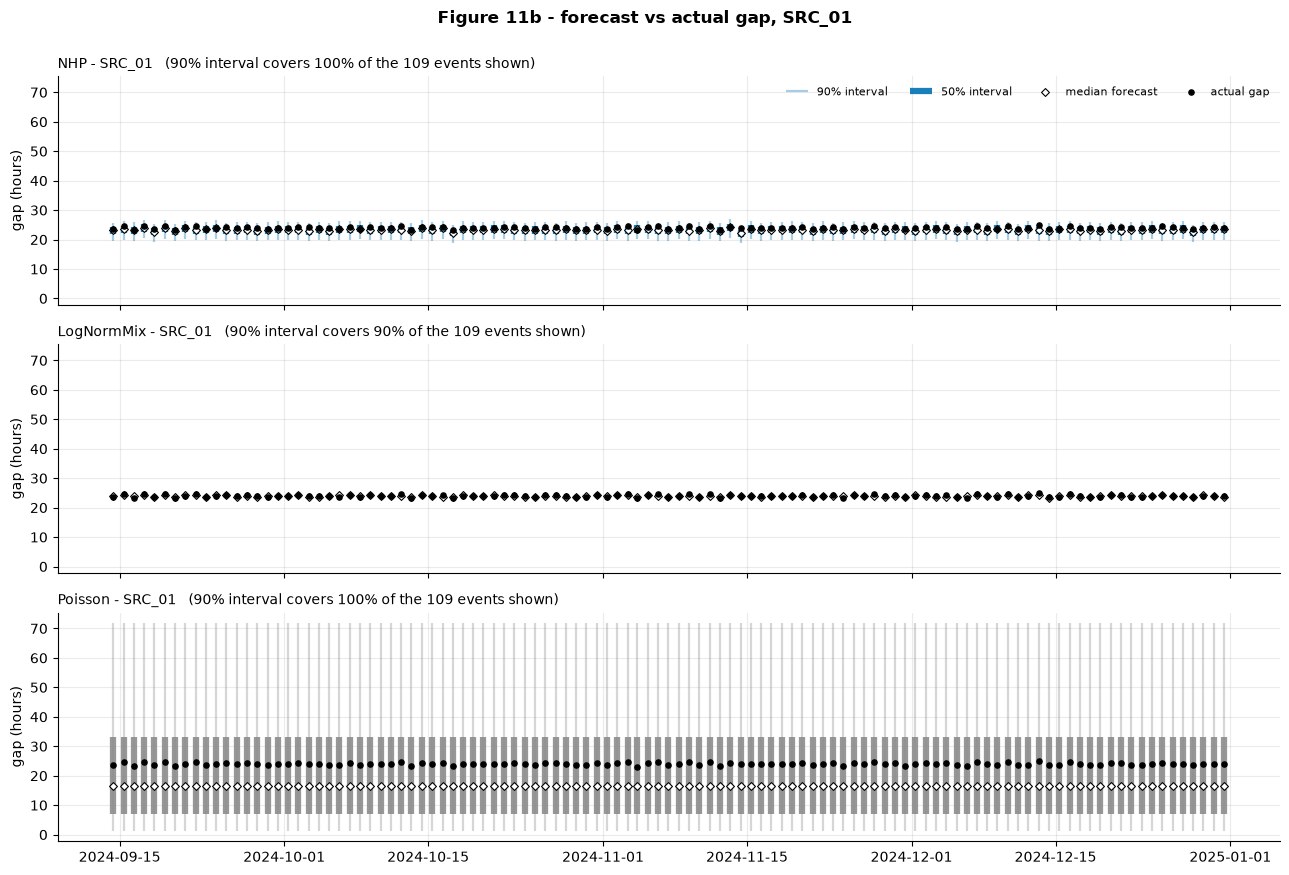

Sources available: SRC_01, SRC_02, SRC_03, SRC_06, SRC_07, SRC_08, SRC_09, SRC_10, SRC_11, SRC_12, SRC_13, SRC_14, SRC_15, SRC_17, SRC_19, SRC_20, SRC_21, SRC_22, SRC_24, SRC_25, SRC_26 - set PE_SOURCE to choose.


In [20]:
PE_SOURCE = None     # e.g. "SRC_06"; None = first source available in the predictions
PE_SEED = 0
PE_LAST_N = 120      # show only the most recent N test events
if PE_OK:
    avail = sorted(P.source_id.unique())
    sid = PE_SOURCE or avail[0]
    models_here = [m for m in NEURAL + ["Poisson"] if ((P.source_id == sid) & (P.model == m)).any()]
    fig, axes = plt.subplots(len(models_here), 1, figsize=(13, 2.9 * len(models_here)), sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    for ax, m in zip(axes, models_here):
        g = P[(P.source_id == sid) & (P.model == m)]
        if m in NEURAL:
            g = g[g.seed == PE_SEED]
        g = g.sort_values("arrival_timestamp").tail(PE_LAST_N)
        t = pd.to_datetime(g.arrival_timestamp)
        # one vertical bar per event (no interpolation between events, which would invent a shape)
        ax.vlines(t, g.q05, g.q95, color=COLORS[m], alpha=0.35, lw=1.6, label="90% interval")
        ax.vlines(t, g.q25, g.q75, color=COLORS[m], alpha=0.9, lw=4.5, label="50% interval")
        ax.scatter(t, g.q50, marker="D", s=16, facecolors="white", edgecolors="black", linewidths=0.8, zorder=3, label="median forecast")
        ax.scatter(t, g.y_true, s=14, color="black", zorder=4, label="actual gap")
        cov90 = ((g.y_true >= g.q05) & (g.y_true <= g.q95)).mean()
        ax.set_title(f"{SHORT[m]} - {sid}   (90% interval covers {cov90:.0%} of the {len(g)} events shown)", fontsize=10, loc="left")
        ax.set_ylabel("gap (hours)")
    axes[0].legend(ncol=4, frameon=False, loc="upper right", fontsize=8)
    fig.suptitle(f"Figure 11b - forecast vs actual gap, {sid}", y=1.0, fontweight="bold"); fig.tight_layout()
    savefig(fig, "fig11b_intervals"); plt.show()
    if PE_SOURCE is None:
        print("Sources available:", ", ".join(avail), "- set PE_SOURCE to choose.")

**Figure 11c - does accuracy collapse on unusually long (or short) gaps?** Each test gap is expressed relative
to its source's typical gap (the median over that source's test events), put in four bins, and the mean NLL
in each bin is computed per source, then the median over sources is shown. Rare long gaps are the operationally
important events, and an average over all events can hide a model failing on them. Numbers above the bars are how
many sources have events in that bin.

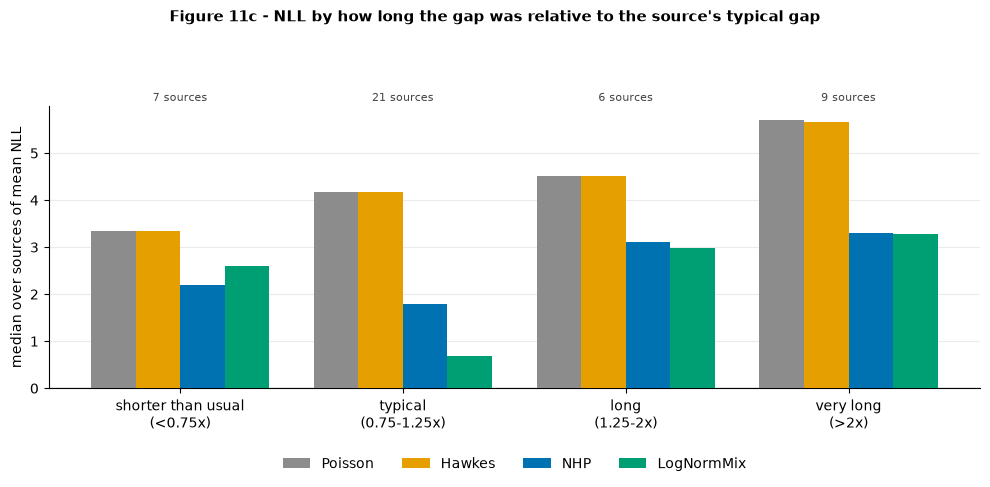

In [21]:
if PE_OK:
    Q = P.copy()
    Q["rel"] = Q.y_true / Q.groupby("source_id").y_true.transform("median")
    bins = [0, 0.75, 1.25, 2.0, np.inf]; labels = ["shorter than usual\n(<0.75x)", "typical\n(0.75-1.25x)", "long\n(1.25-2x)", "very long\n(>2x)"]
    Q["bin"] = pd.cut(Q.rel, bins=bins, labels=labels)
    per = Q.groupby(["source_id", "model", "bin"], observed=True).nll.mean().reset_index()
    med = per.groupby(["model", "bin"], observed=True).nll.median().unstack("bin").reindex(columns=labels)
    cnt = per.groupby("bin", observed=True).source_id.nunique().reindex(labels).fillna(0)   # empty bins -> 0 sources
    fig, ax = plt.subplots(figsize=(10, 4.6))
    ms = [m for m in MODEL_ORDER if m in med.index]
    w = 0.8 / len(ms)
    for i, m in enumerate(ms):
        ax.bar(np.arange(len(labels)) + (i - (len(ms) - 1) / 2) * w, med.loc[m], width=w, color=COLORS[m], label=SHORT[m], zorder=3)
    for j, c in enumerate(cnt):
        ax.text(j, 1.01, f"{int(c)} sources", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8, color="#444")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels); ax.grid(axis="x", visible=False)
    ax.set_ylabel("median over sources of mean NLL"); ax.legend(frameon=False, ncol=len(ms), loc="upper center", bbox_to_anchor=(0.5, -0.2))
    fig.suptitle("Figure 11c - NLL by how long the gap was relative to the source's typical gap", y=1.08, fontweight="bold", fontsize=11)
    fig.tight_layout(); savefig(fig, "fig11c_nll_by_gap_size"); plt.show()

## Caveats to keep in mind when interpreting

- **Few seeds, few sources.** Three seeds do not bound training variance (Figure 4), and the 21-25 sources are
  hand-designed scenarios rather than a random sample, so p-values in section 1 are descriptive.
- **`low_n` sources** (3 or fewer test events here) are shown but excluded from headline statistics; a single
  event moves their metrics a lot. Flip `EXCLUDE_LOW_N` to include them.
- **Raw NLL and CRPS are in hours and scale with the source's cadence.** Compare models within a source, and use
  gains/skill scores across sources.
- **Schedule groups are subjective** (see `SOURCE_GROUPS`), and several groups contain only 1-3 sources.
- **Early-stopped neural models with `hit_cap`** (section 10) may be under-trained, so a comparison with them
  reflects the training budget as well as the model class.
- Figures are saved to `<run>/figures/` as PNG and PDF for use in the report.